# 06 Spline GAM (logistic with spline terms)
A generalized additive model: each continuous feature gets a smooth curve (cubic B-splines) instead of a straight line, and the curves add up on the log-odds scale. It captures non-linear shapes like the steep drop in quit risk over the first few years while staying explainable feature by feature.

Starts from the pruned linear feature set (collinearity still matters here). L2 penalty `C` and the number of knots are tuned by CV.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))   # project root, so `src` is importable

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import RocCurveDisplay

from src.modeling import (SEED, get_cv, load_split, linear_features, pruned_linear_features,
                          raw_features, vif, best_cv_scores, cv_summary, finalize, load_scores)

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_rows", 80)

fs = load_split()
X_train, y_train, X_test, y_test = fs.X_train, fs.y_train, fs.X_test, fs.y_test
cv = get_cv()   # 5-fold x 5 repeats, stratified, same splits in every notebook
print(X_train.shape, X_test.shape, "| train quit rate", round(y_train.mean(), 3))

(1170, 53) (300, 53) | train quit rate 0.158


In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import SplineTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

cols = pruned_linear_features(X_train, verbose=False)
spline_cols = [c for c in cols if X_train[c].nunique() > 10]   # continuous -> smooth curves
linear_cols = [c for c in cols if c not in spline_cols]          # binary / dummies -> linear
print("spline terms:", spline_cols)
print("linear terms:", len(linear_cols))

spline terms: ['Age', 'DistanceFromHome', 'MostRecentPerfEval', 'YearsSinceLastPromotion', 'TenureRatio', 'RoleRatio', 'MgrRatio', 'PromoGap', 'AvgYearsPerCompany', 'LogIncome', 'IncomePerYearWork']
linear terms: 21


In [3]:
pre = ColumnTransformer([
    ("spline", SplineTransformer(degree=3, n_knots=4, knots="quantile", extrapolation="linear"), spline_cols),
    ("linear", StandardScaler(), linear_cols),
])
gam = Pipeline([("pre", pre), ("scale", StandardScaler()), ("logit", LogisticRegression(max_iter=5000))])
grid = {"pre__spline__n_knots": [3, 4, 5, 6], "logit__C": np.logspace(-3, 0, 10)}
search = GridSearchCV(gam, grid, cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train[cols], y_train)
gam_scores = best_cv_scores(search)
print("best:", search.best_params_, "|", cv_summary(gam_scores))

best: {'logit__C': np.float64(0.046415888336127774), 'pre__spline__n_knots': 3} | CV AUC 0.8141 +/- 0.0386 (25 folds)


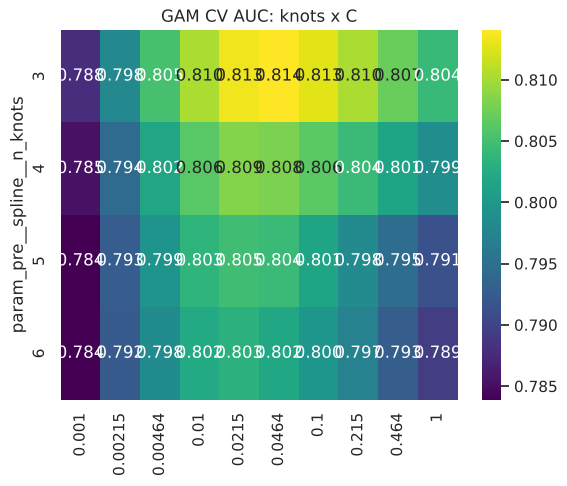

In [4]:
piv = pd.DataFrame(search.cv_results_).pivot_table(index="param_pre__spline__n_knots",
                                                   columns="param_logit__C", values="mean_test_score")
piv.columns = [f"{c:.3g}" for c in piv.columns]
sns.heatmap(piv, annot=True, fmt=".3f", cmap="viridis"); plt.title("GAM CV AUC: knots x C"); plt.show()

## Shape of the main effects
Partial dependence on the predicted quit probability (training data), for the continuous terms.

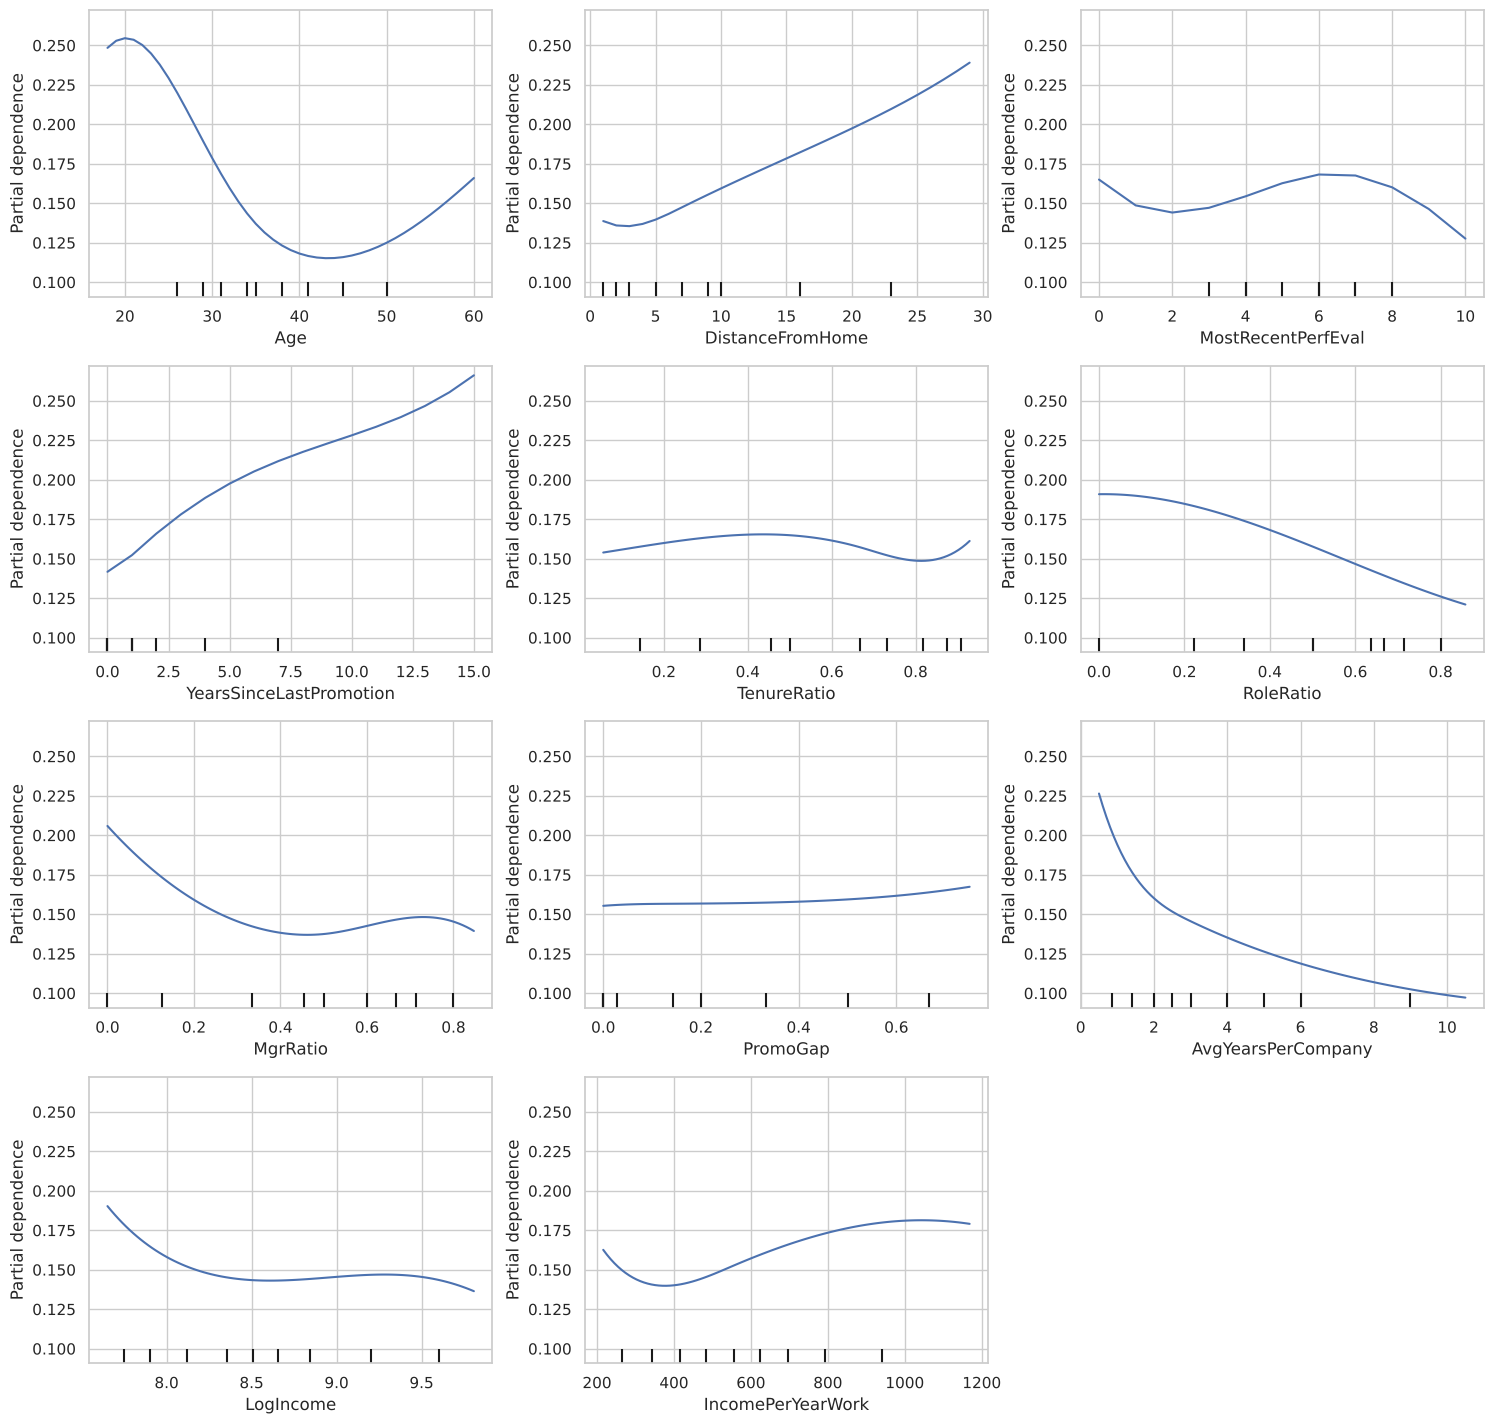

In [5]:
from sklearn.inspection import PartialDependenceDisplay

gam_best = search.best_estimator_
n = len(spline_cols)
fig, axes = plt.subplots(int(np.ceil(n / 3)), 3, figsize=(15, 3.6 * int(np.ceil(n / 3))))
PartialDependenceDisplay.from_estimator(gam_best, X_train[cols].astype(float), spline_cols, ax=axes.ravel()[:n],
                                        kind="average", response_method="predict_proba")
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.tight_layout(); plt.show()

## Test set (scored once)
The model is frozen above. This is the only cell that touches `y_test`. It also saves test predictions and out-of-fold training predictions to `results/preds/` for blending later.

In [6]:
finalize("spline_gam", gam_best, X_train[cols], y_train, X_test[cols], y_test,
         fs.id_train, fs.id_test, gam_scores,
         notes=", ".join(f"{k.split('__')[-1]}={v:.3g}" for k, v in search.best_params_.items()));

spline_gam: CV AUC 0.8141 +/- 0.0386 (25 folds) | TEST AUC 0.7839


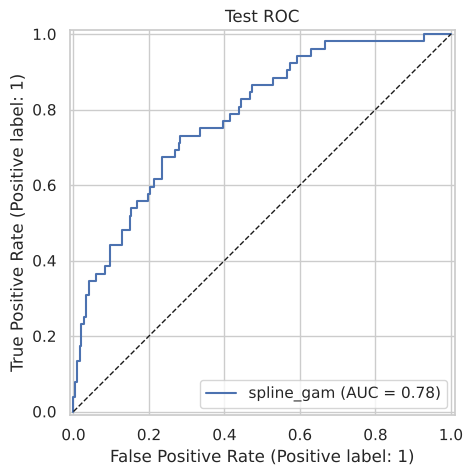

In [7]:
p_test = gam_best.predict_proba(X_test[cols])[:, 1]
fig, ax = plt.subplots(figsize=(5, 5))
RocCurveDisplay.from_predictions(y_test, p_test, name="spline_gam", ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_title("Test ROC")
plt.show()

## Leaderboard so far

In [8]:
load_scores()

,model,cv_auc_mean,cv_auc_std,test_auc,n_features,notes
0,logit_elasticnet,0.8182,0.0374,0.7650,47,"C=0.0681, l1_ratio=0.1"
1,logit_l1,0.8165,0.0388,0.7690,47,C=0.316
2,logit_plain_pruned,0.8153,0.0411,0.7760,32,"no penalty, hand + VIF pruned"
3,spline_gam,0.8141,0.0386,0.7839,32,"C=0.0464, n_knots=3"
4,extra_trees,0.8028,0.0398,0.7423,32,"features=pruned_linear; min_samples_leaf=5, ma..."
5,lightgbm,0.8010,0.0336,0.7616,32,"features=pruned_linear; subsample=0.6, reg_lam..."
6,random_forest,0.7972,0.0361,0.7369,32,"features=pruned_linear; min_samples_leaf=5, ma..."
